# Learning When to Act
### A Comparative Case Study of SARSA, Q-Learning, Expected SARSA and Bandit Policies under Different Exploration Strategies for Adaptive Toxic Content Moderation

**How to run (Colab):** `Runtime → Run all`. When asked, upload the Jigsaw `train.csv` (or `train.csv.zip`).

* Dataset: Kaggle *Jigsaw Toxic Comment Classification Challenge* → `train.csv`
  (or place `kaggle.json` in `/content` and the notebook downloads it automatically; you must accept the competition rules on Kaggle first).
* No file? The notebook falls back to a small **DEMO** corpus so everything still runs (results are then only illustrative).
* Set `QUICK = True` in the config cell for a fast trial run (~1–2 min). The full run takes roughly 5–10 min on a standard CPU runtime.
* The last section launches an interactive **Gradio interface** with a public link.

**Pipeline:** comment → toxicity classifier → probability → RL agent (state = score bin, review budget, queue position) → Approve / Escalate / Remove.

## 1. Setup

In [2]:
!pip -q install gradio

import os, math, glob, time, zipfile, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score, average_precision_score

warnings.filterwarnings("ignore")
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)
print("Running in Colab:", IN_COLAB)

Running in Colab: True


## 2. Configuration
All design assumptions live here. Reward values are **assumptions, not measured platform costs** — Section 9 runs a sensitivity analysis over them.

In [3]:
QUICK = False            # True = fast trial run
DATA_SOURCE = "auto"     # "auto" (kaggle.json if present, else upload), "upload", "kaggle", "demo"
USE_TRANSFORMER = False  # True = also score comments with a pretrained transformer (use a GPU runtime)
TRANSFORMER_MODEL = "unitary/toxic-bert"
MAX_TRANSFORMER_COMMENTS = 6000

CFG = dict(
    N_SEEDS=20,            # random seeds per agent (main experiment)
    N_SEEDS_SMALL=10,      # seeds for sensitivity / classifier-quality experiments
    N_EPISODES=500,        # training episodes per run
    EP_LEN=100,            # comments per episode (one moderation "shift")
    BUDGET=15,             # human reviews available per episode
    N_BINS=10,             # toxicity score bins
    GAMMA=0.95,            # discount for TD methods (bandits use 0)
    ALPHA=0.1,             # constant step size (lets agents track change)
    EPS=0.1,               # fixed epsilon
    EPS_START=1.0, EPS_MIN=0.02, DECAY_EPISODES=300,
    UCB_C=1.0,
    TS_SIGMA=2.0,          # Thompson Sampling prior scale
    TOXIC_RATE=0.10,       # share of toxic comments before drift
    DRIFT_EPISODE=250,     # when conditions change
    DRIFT_TOXIC_RATE=0.25, # share of toxic comments after drift
    DRIFT_REVIEW_COST=1.0, # review cost after drift
    EVAL_EPISODES=100,
)
REWARDS = dict(
    correct=1.0,        # right approve / right remove
    miss=-5.0,          # toxic comment approved
    false_remove=-3.0,  # clean comment removed
    review_cost=0.5,    # cost of one human review (human decides correctly)
    no_budget=-1.0,     # tried to escalate with no reviewers left (comment auto-approved)
)
if QUICK:
    CFG.update(N_SEEDS=5, N_SEEDS_SMALL=3, N_EPISODES=200, DRIFT_EPISODE=100,
               DECAY_EPISODES=120, EVAL_EPISODES=30)

ACTIONS = ["Approve", "Escalate", "Remove"]
N_ACTIONS = 3
N_BUDGET_BINS = 5
N_TIME_BINS = 4
N_STATES = CFG["N_BINS"] * N_BUDGET_BINS * N_TIME_BINS
print("States:", N_STATES, "| Actions:", N_ACTIONS)

States: 200 | Actions: 3


## 3. Load the Jigsaw dataset

In [5]:
LABEL_COLS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]

def _find_train_csv():
    for p in ["train.csv", "train.csv.zip", "/content/train.csv", "/content/train.csv.zip",
              "jigsaw/train.csv", "jigsaw/train.csv.zip"]:
        if os.path.exists(p):
            return p
    return None

def _try_kaggle():
    home_key = os.path.expanduser("~/.kaggle/kaggle.json")
    if not os.path.exists(home_key):
        if os.path.exists("kaggle.json"):
            os.makedirs(os.path.dirname(home_key), exist_ok=True)
            shutil.copy("kaggle.json", home_key)
            os.chmod(home_key, 0o600)
        else:
            return False
    os.system("pip -q install kaggle")
    rc = os.system("kaggle competitions download -c jigsaw-toxic-comment-classification-challenge -p jigsaw -q")
    zp = "jigsaw/jigsaw-toxic-comment-classification-challenge.zip"
    if rc != 0 or not os.path.exists(zp):
        print("Kaggle download failed (did you accept the competition rules?)")
        return False
    with zipfile.ZipFile(zp) as z:
        z.extractall("jigsaw")
    return True

def make_demo_corpus(n=20000, seed=0):
    # Small synthetic corpus so the notebook runs without the real dataset.
    rng = np.random.default_rng(seed)
    topics = ["the election", "this article", "the new policy", "the match", "the movie", "climate data",
              "the edit", "the citation", "the budget", "this page"]
    clean_t = ["I think {t} needs a better source.", "Thanks for fixing {t}, looks good now.",
               "Can someone explain {t} in more detail?", "I disagree with {t} but respect the view.",
               "Please discuss {t} on the talk page first.", "Good point about {t}."]
    insults = ["idiot", "stupid", "moron", "loser", "pathetic", "dumb", "clown", "trash"]
    tox_t = ["You are a {i}, stop editing {t}.", "Only a {i} would write {t}.",
             "Shut up you {i}.", "{t} was written by a {i}, get lost.", "What a {i} take on {t}, you {i2}."]
    rows = []
    for _ in range(n):
        t = rng.choice(topics)
        if rng.random() < 0.10:
            s = rng.choice(tox_t).format(t=t, i=rng.choice(insults), i2=rng.choice(insults)); y = 1
        else:
            s = rng.choice(clean_t).format(t=t); y = 0
            if rng.random() < 0.05:   # hard cases: clean text with a harsh word
                s += " That argument is " + rng.choice(["dumb", "trash", "pathetic"]) + "."
        if rng.random() < 0.05:       # label noise
            y = 1 - y
        rows.append((s, y))
    return pd.DataFrame(rows, columns=["text", "label"])

def load_data():
    path = _find_train_csv()
    if path is None and DATA_SOURCE in ("auto", "kaggle") and _try_kaggle():
        path = _find_train_csv()
    if path is None and IN_COLAB and DATA_SOURCE in ("auto", "upload"):
        from google.colab import files
        print("Please upload Jigsaw train.csv or train.csv.zip")
        files.upload()
        path = _find_train_csv()
    if path is None or DATA_SOURCE == "demo":
        print("WARNING: Jigsaw not found -> using DEMO corpus (results are only illustrative).")
        return make_demo_corpus(), True
    df = pd.read_csv(path)
    df["label"] = (df[LABEL_COLS].sum(axis=1) > 0).astype(int)
    df = df.rename(columns={"comment_text": "text"})[["text", "label"]]
    return df, False

df, DEMO_MODE = load_data()
df = df.dropna().reset_index(drop=True)
print(f"Comments: {len(df):,} | toxic share: {df.label.mean():.3f} | demo mode: {DEMO_MODE}")

Please upload Jigsaw train.csv or train.csv.zip


Saving train.csv to train.csv
Comments: 159,571 | toxic share: 0.102 | demo mode: False


## 4. Data split (no leakage)
* **60%** trains the toxicity classifier.
* **40%** is held out for the RL environment (the classifier never sees it): half for agent training, half for final evaluation.

In [6]:
clf_df, env_df = train_test_split(df, test_size=0.4, stratify=df.label, random_state=42)
env_train_df, env_test_df = train_test_split(env_df, test_size=0.5, stratify=env_df.label, random_state=42)
clf_df, env_train_df, env_test_df = [d.reset_index(drop=True) for d in (clf_df, env_train_df, env_test_df)]
print(f"Classifier train: {len(clf_df):,} | RL train pool: {len(env_train_df):,} | RL test pool: {len(env_test_df):,}")

Classifier train: 95,742 | RL train pool: 31,914 | RL test pool: 31,915


## 5. Toxicity classifier (TF-IDF + Logistic Regression)
Produces the probability the agent observes. (Swap in your BiLSTM/transformer scores from the transformer case study if you have them.)

Trained in 27.0s
Held-out quality: {'AUC': np.float64(0.972), 'PR_AUC': np.float64(0.873), 'F1_at_0_5': 0.756}


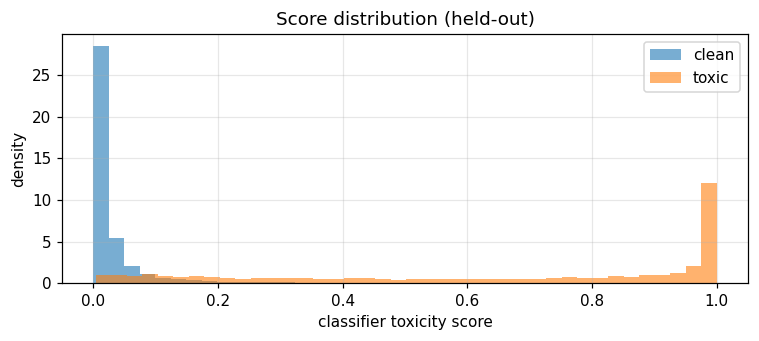

In [7]:
t0 = time.time()
vec = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), sublinear_tf=True, min_df=2, strip_accents="unicode")
X_clf = vec.fit_transform(clf_df.text)
clf = LogisticRegression(C=4.0, max_iter=2000, solver="liblinear")
clf.fit(X_clf, clf_df.label)

def score_texts(texts):
    return clf.predict_proba(vec.transform(list(texts)))[:, 1]

env_train_scores = score_texts(env_train_df.text)
env_test_scores = score_texts(env_test_df.text)
env_train_labels = env_train_df.label.values
env_test_labels = env_test_df.label.values

def clf_report(scores, labels):
    return dict(AUC=roc_auc_score(labels, scores), PR_AUC=average_precision_score(labels, scores),
                F1_at_0_5=f1_score(labels, scores >= 0.5))

print(f"Trained in {time.time()-t0:.1f}s")
print("Held-out quality:", {k: round(v, 3) for k, v in clf_report(env_test_scores, env_test_labels).items()})

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(env_test_scores[env_test_labels == 0], bins=40, alpha=0.6, label="clean", density=True)
ax.hist(env_test_scores[env_test_labels == 1], bins=40, alpha=0.6, label="toxic", density=True)
ax.set_xlabel("classifier toxicity score"); ax.set_ylabel("density"); ax.set_title("Score distribution (held-out)")
ax.legend(); plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/score_distribution.png"); plt.show()

### 5b. Classifier-quality variants (Objective 6)
* **Degraded**: the same scores with added noise, simulating a weaker model (e.g. a small BiLSTM).
* **Transformer** (optional, `USE_TRANSFORMER=True`): pretrained `unitary/toxic-bert`. Note: that model was trained on Jigsaw, so treat its numbers as an upper bound, not a leakage-free result.

In [8]:
def degrade(scores, noise_sd=1.5, seed=0):
    rng = np.random.default_rng(seed)
    p = np.clip(scores, 1e-6, 1 - 1e-6)
    logit = np.log(p / (1 - p)) * 0.6 + rng.normal(0, noise_sd, len(p))
    return 1 / (1 + np.exp(-logit))

CLASSIFIERS = {
    "TF-IDF + LogReg": (env_train_scores, env_train_labels, env_test_scores, env_test_labels),
    "Degraded (weak model)": (degrade(env_train_scores, seed=1), env_train_labels,
                              degrade(env_test_scores, seed=2), env_test_labels),
}

if USE_TRANSFORMER and not DEMO_MODE:
    import torch
    from transformers import pipeline
    pipe = pipeline("text-classification", model=TRANSFORMER_MODEL, top_k=None, truncation=True,
                    max_length=256, function_to_apply="sigmoid",
                    device=0 if torch.cuda.is_available() else -1)
    def bert_scores(texts):
        out = pipe(list(texts), batch_size=64)
        return np.array([{d["label"].lower(): d["score"] for d in o}.get("toxic", max(d["score"] for d in o)) for o in out])
    rng = np.random.default_rng(0)
    tr_i = rng.choice(len(env_train_df), min(MAX_TRANSFORMER_COMMENTS, len(env_train_df)), replace=False)
    te_i = rng.choice(len(env_test_df), min(MAX_TRANSFORMER_COMMENTS, len(env_test_df)), replace=False)
    t0 = time.time()
    CLASSIFIERS["Transformer (toxic-bert)"] = (bert_scores(env_train_df.text.values[tr_i]), env_train_labels[tr_i],
                                               bert_scores(env_test_df.text.values[te_i]), env_test_labels[te_i])
    print(f"Transformer scoring done in {time.time()-t0:.0f}s")

clf_quality = pd.DataFrame({k: clf_report(v[2], v[3]) for k, v in CLASSIFIERS.items()}).T.round(3)
clf_quality

,AUC,PR_AUC,F1_at_0_5
TF-IDF + LogReg,0.972,0.873,0.756
Degraded (weak model),0.891,0.666,0.581


## 6. The moderation MDP
* **State** = (toxicity score bin [10], remaining review budget bin [5], position in the shift [4]) → 200 states
* **Actions** = Approve, Escalate (human review), Remove
* **Reward**: +1 correct, −5 missed toxic, −3 false removal, escalation = +1 − review cost (human is assumed correct), escalating with no budget left = comment auto-approved + −1
* **Drift**: at `DRIFT_EPISODE` the toxic share rises 10% → 25% and review cost rises 0.5 → 1.0

In [9]:
def encode_state(score, budget, t, cfg=CFG):
    sb = min(int(score * cfg["N_BINS"]), cfg["N_BINS"] - 1)
    bb = math.ceil((N_BUDGET_BINS - 1) * budget / cfg["BUDGET"]) if cfg["BUDGET"] > 0 else 0
    tb = min(N_TIME_BINS - 1, int(N_TIME_BINS * t / cfg["EP_LEN"]))
    return (sb * N_BUDGET_BINS + bb) * N_TIME_BINS + tb

class ModerationEnv:
    def __init__(self, scores, labels, seed, rewards, cfg=CFG):
        self.scores = np.asarray(scores, dtype=float)
        self.labels = np.asarray(labels).astype(int)
        self.tox = np.flatnonzero(self.labels == 1)
        self.cln = np.flatnonzero(self.labels == 0)
        self.rng = np.random.default_rng(seed)
        self.R = dict(rewards)
        self.cfg = cfg
        self.toxic_rate = cfg["TOXIC_RATE"]

    def set_conditions(self, toxic_rate=None, review_cost=None):
        if toxic_rate is not None: self.toxic_rate = toxic_rate
        if review_cost is not None: self.R["review_cost"] = review_cost

    def reset(self):
        n = self.cfg["EP_LEN"]
        is_tox = self.rng.random(n) < self.toxic_rate
        self.ep_idx = np.where(is_tox, self.rng.choice(self.tox, n), self.rng.choice(self.cln, n))
        self.ep_scores = self.scores[self.ep_idx].tolist()
        self.ep_labels = self.labels[self.ep_idx].tolist()
        self.t, self.budget = 0, self.cfg["BUDGET"]
        return self._state()

    @property
    def current_score(self):
        return self.ep_scores[self.t]

    def _state(self):
        return encode_state(self.ep_scores[self.t], self.budget, self.t, self.cfg)

    def step(self, a):
        y, R = self.ep_labels[self.t], self.R
        if a == 0:
            outcome = "miss" if y else "correct"
        elif a == 2:
            outcome = "correct" if y else "false_remove"
        elif self.budget > 0:
            self.budget -= 1
            outcome = "escalated"
        else:
            outcome = "no_budget_miss" if y else "no_budget"
        reward = {"correct": R["correct"], "miss": R["miss"], "false_remove": R["false_remove"],
                  "escalated": R["correct"] - R["review_cost"],
                  "no_budget": R["correct"] + R["no_budget"],
                  "no_budget_miss": R["miss"] + R["no_budget"]}[outcome]
        self.t += 1
        done = self.t >= self.cfg["EP_LEN"]
        return (None if done else self._state()), reward, done, outcome

## 7. Agents
| Family | Learning rule | Exploration |
|---|---|---|
| Fixed baselines | none | none |
| Contextual bandit (γ = 0) | incremental value estimate | greedy, ε-greedy, decaying ε, UCB, Thompson |
| SARSA (on-policy) | Q(s,a) ← r + γQ(s′,a′) | ε-greedy, decaying ε |
| Q-Learning (off-policy) | Q(s,a) ← r + γ max Q(s′,·) | greedy, ε-greedy, decaying ε, UCB, Thompson |
| Expected SARSA | Q(s,a) ← r + γ Σπ(a′|s′)Q(s′,a′) | ε-greedy, decaying ε |

Q-tables start with tiny random values to break ties. A constant step size α lets agents track the drift.

In [10]:
class TabularAgent:
    def __init__(self, algo, explore, seed, cfg=CFG, n_states=N_STATES):
        self.algo, self.explore, self.cfg = algo, explore, cfg
        self.rng = np.random.default_rng(seed + 7919)
        self.Q = self.rng.random((n_states, N_ACTIONS)) * 1e-4
        self.N = np.zeros((n_states, N_ACTIONS))
        self.gamma = 0.0 if algo == "bandit" else cfg["GAMMA"]
        self.decay = (cfg["EPS_MIN"] / cfg["EPS_START"]) ** (1 / max(1, cfg["DECAY_EPISODES"]))

    def epsilon(self, ep):
        if self.explore == "eps": return self.cfg["EPS"]
        if self.explore == "decay": return max(self.cfg["EPS_MIN"], self.cfg["EPS_START"] * self.decay ** ep)
        return 0.0

    def act(self, s, ep, env=None, greedy=False):
        q = self.Q[s]
        if greedy or self.explore == "greedy":
            return int(q.argmax())
        if self.explore in ("eps", "decay"):
            if self.rng.random() < self.epsilon(ep):
                return int(self.rng.integers(N_ACTIONS))
            return int(q.argmax())
        n = self.N[s]
        if self.explore == "ucb":
            if (n == 0).any():
                return int(np.flatnonzero(n == 0)[0])
            return int((q + self.cfg["UCB_C"] * np.sqrt(np.log(n.sum()) / n)).argmax())
        if self.explore == "thompson":
            return int((q + self.rng.normal(0, 1, N_ACTIONS) * self.cfg["TS_SIGMA"] / np.sqrt(n + 1)).argmax())
        raise ValueError(self.explore)

    def _policy_probs(self, s, ep):
        e = self.epsilon(ep) if self.explore in ("eps", "decay") else self.cfg["EPS"]
        p = np.full(N_ACTIONS, e / N_ACTIONS)
        p[int(self.Q[s].argmax())] += 1 - e
        return p

    def update(self, s, a, r, s2, a2, done, ep):
        self.N[s, a] += 1
        if done or self.gamma == 0.0:
            target = r
        elif self.algo == "sarsa":
            target = r + self.gamma * self.Q[s2, a2]
        elif self.algo == "qlearning":
            target = r + self.gamma * self.Q[s2].max()
        elif self.algo == "expected_sarsa":
            target = r + self.gamma * float(self._policy_probs(s2, ep) @ self.Q[s2])
        else:
            target = r
        self.Q[s, a] += self.cfg["ALPHA"] * (target - self.Q[s, a])

class ThresholdAgent:
    # Single threshold: remove if p >= low.  Two thresholds: approve < low <= escalate < high <= remove.
    def __init__(self, low, high=None):
        self.low, self.high = low, high
    def act(self, s, ep, env=None, greedy=False):
        p = env.current_score
        if self.high is None:
            return 2 if p >= self.low else 0
        if p >= self.high: return 2
        if p >= self.low:  return 1 if env.budget > 0 else (2 if p >= 0.5 else 0)
        return 0
    def update(self, *args): pass

AGENT_SPECS = {
    "Threshold 0.5":           ("fixed", (0.5, None)),
    "Two-threshold 0.3/0.7":   ("fixed", (0.3, 0.7)),
    "Bandit · Greedy":         ("bandit", "greedy"),
    "Bandit · ε-greedy":       ("bandit", "eps"),
    "Bandit · Decaying ε":     ("bandit", "decay"),
    "Bandit · UCB":            ("bandit", "ucb"),
    "Bandit · Thompson":       ("bandit", "thompson"),
    "SARSA · ε-greedy":        ("sarsa", "eps"),
    "SARSA · Decaying ε":      ("sarsa", "decay"),
    "Q-Learning · Greedy":     ("qlearning", "greedy"),
    "Q-Learning · ε-greedy":   ("qlearning", "eps"),
    "Q-Learning · Decaying ε": ("qlearning", "decay"),
    "Q-Learning · UCB":        ("qlearning", "ucb"),
    "Q-Learning · Thompson":   ("qlearning", "thompson"),
    "Exp. SARSA · ε-greedy":   ("expected_sarsa", "eps"),
    "Exp. SARSA · Decaying ε": ("expected_sarsa", "decay"),
}

def make_agent(spec, seed, cfg=CFG):
    algo, arg = spec
    if algo == "fixed":
        return ThresholdAgent(*arg)
    return TabularAgent(algo, arg, seed, cfg)

## 8. Training & evaluation loop

In [11]:
METRICS = ["Reward", "Missed toxic", "False removals", "Escalations"]

def run_episode(env, agent, ep, learn=True, greedy=False):
    s = env.reset()
    a = agent.act(s, ep, env, greedy)
    tot = miss = fr = esc = 0.0
    while True:
        s2, r, done, out = env.step(a)
        a2 = None if done else agent.act(s2, ep, env, greedy)
        if learn:
            agent.update(s, a, r, s2, a2, done, ep)
        tot += r
        miss += out in ("miss", "no_budget_miss")
        fr += out == "false_remove"
        esc += out == "escalated"
        if done:
            return tot, miss, fr, esc
        s, a = s2, a2

def train(spec, scores, labels, seed, rewards, drift=True, cfg=CFG):
    env = ModerationEnv(scores, labels, seed, rewards, cfg)
    agent = make_agent(spec, seed, cfg)
    hist = np.zeros((cfg["N_EPISODES"], 4))
    for ep in range(cfg["N_EPISODES"]):
        if drift and ep == cfg["DRIFT_EPISODE"]:
            env.set_conditions(cfg["DRIFT_TOXIC_RATE"], cfg["DRIFT_REVIEW_COST"])
        hist[ep] = run_episode(env, agent, ep)
    return agent, hist

def evaluate(agent, scores, labels, seed, rewards, toxic_rate, review_cost, cfg=CFG):
    env = ModerationEnv(scores, labels, seed, rewards, cfg)
    env.set_conditions(toxic_rate, review_cost)
    return np.mean([run_episode(env, agent, 10**9, learn=False, greedy=True)
                    for _ in range(cfg["EVAL_EPISODES"])], axis=0)

def run_all(specs, tr_s, tr_y, te_s, te_y, rewards, n_seeds, drift=True, cfg=CFG, verbose=True):
    curves, evals, agents = {}, {}, {}
    tox = cfg["DRIFT_TOXIC_RATE"] if drift else cfg["TOXIC_RATE"]
    cost = cfg["DRIFT_REVIEW_COST"] if drift else rewards["review_cost"]
    for name, spec in specs.items():
        t0, H, E = time.time(), [], []
        for seed in range(n_seeds):
            ag, h = train(spec, tr_s, tr_y, seed, rewards, drift, cfg)
            H.append(h)
            E.append(evaluate(ag, te_s, te_y, seed + 10_000, rewards, tox, cost, cfg))
            if seed == 0:
                agents[name] = ag
        curves[name], evals[name] = np.stack(H), np.stack(E)
        if verbose:
            print(f"{name:<26} eval reward {evals[name][:,0].mean():8.1f}   ({time.time()-t0:.1f}s)")
    return curves, evals, agents

def ci95(x, axis=0):
    n = x.shape[axis]
    return 1.96 * x.std(axis=axis, ddof=1) / np.sqrt(n) if n > 1 else np.zeros_like(x.mean(axis=axis))

def summarize(evals, curves=None, cfg=CFG, w=50):
    rows = []
    for name, E in evals.items():
        m, c = E.mean(0), ci95(E)
        row = {"Policy": name}
        for i, k in enumerate(METRICS):
            row[k] = f"{m[i]:.1f} ± {c[i]:.1f}"
        if curves is not None:
            H, d = curves[name][:, :, 0], cfg["DRIFT_EPISODE"]
            row["Train reward pre-drift"] = round(H[:, max(0, d - w):d].mean(), 1)
            row["Right after drift"] = round(H[:, d:d + w].mean(), 1)
            row["End of training"] = round(H[:, -w:].mean(), 1)
        row["_r"] = m[0]
        rows.append(row)
    return pd.DataFrame(rows).sort_values("_r", ascending=False).drop(columns="_r").reset_index(drop=True)

### 8a. Main experiment (with drift)

In [12]:
t_start = time.time()
CURVES, EVALS, AGENTS = run_all(AGENT_SPECS, env_train_scores, env_train_labels,
                                env_test_scores, env_test_labels, REWARDS, CFG["N_SEEDS"], drift=True)
print(f"\nTotal: {(time.time()-t_start)/60:.1f} min")
RESULTS = summarize(EVALS, CURVES)
RESULTS.to_csv(f"{RESULTS_DIR}/main_results.csv", index=False)
print("Evaluation = greedy policy on the held-out pool under post-drift conditions; mean ± 95% CI over seeds")
RESULTS

Threshold 0.5              eval reward     45.3   (3.1s)
Two-threshold 0.3/0.7      eval reward     57.3   (3.1s)
Bandit · Greedy            eval reward     53.8   (5.2s)
Bandit · ε-greedy          eval reward     59.4   (6.4s)
Bandit · Decaying ε        eval reward     54.1   (6.8s)
Bandit · UCB               eval reward     53.6   (17.1s)
Bandit · Thompson          eval reward     57.5   (13.1s)
SARSA · ε-greedy           eval reward     55.6   (7.0s)
SARSA · Decaying ε         eval reward     58.0   (7.4s)
Q-Learning · Greedy        eval reward     46.3   (8.5s)
Q-Learning · ε-greedy      eval reward     53.3   (10.1s)
Q-Learning · Decaying ε    eval reward     55.0   (10.7s)
Q-Learning · UCB           eval reward     62.0   (21.4s)
Q-Learning · Thompson      eval reward     58.7   (17.9s)
Exp. SARSA · ε-greedy      eval reward     58.6   (13.8s)
Exp. SARSA · Decaying ε    eval reward     60.1   (14.3s)

Total: 2.8 min
Evaluation = greedy policy on the held-out pool under post-drift

,Policy,Reward,Missed toxic,False removals,Escalations,Train reward pre-drift,Right after drift,End of training
0,Q-Learning · UCB,62.0 ± 1.2,3.3 ± 0.2,1.1 ± 0.2,13.4 ± 0.5,82.3,59.3,61.7
1,Exp. SARSA · Decaying ε,60.1 ± 1.6,3.7 ± 0.3,0.7 ± 0.1,14.7 ± 0.2,74.1,54.2,56.8
2,Bandit · ε-greedy,59.4 ± 3.4,2.6 ± 0.1,2.1 ± 0.4,14.5 ± 0.4,58.3,39.8,42.1
3,Q-Learning · Thompson,58.7 ± 1.7,3.9 ± 0.2,0.9 ± 0.1,13.9 ± 0.5,80.4,52.8,57.6
4,Exp. SARSA · ε-greedy,58.6 ± 2.6,3.0 ± 0.2,1.9 ± 0.3,14.9 ± 0.1,60.6,34.2,41.2
5,SARSA · Decaying ε,58.0 ± 1.6,4.0 ± 0.3,0.7 ± 0.1,14.8 ± 0.1,72.0,50.6,54.6
6,Bandit · Thompson,57.5 ± 1.3,2.5 ± 0.1,3.0 ± 0.3,14.9 ± 0.1,71.4,49.8,52.6
7,Two-threshold 0.3/0.7,57.3 ± 0.9,5.9 ± 0.1,0.2 ± 0.0,6.6 ± 0.1,83.0,57.0,57.1
8,SARSA · ε-greedy,55.6 ± 2.6,3.2 ± 0.2,1.7 ± 0.2,14.8 ± 0.1,60.2,34.3,40.9
9,Q-Learning · Decaying ε,55.0 ± 1.3,3.8 ± 0.3,1.7 ± 0.3,14.9 ± 0.2,68.0,44.8,51.6


### 8b. Learning curves (mean ± 95% CI across seeds)

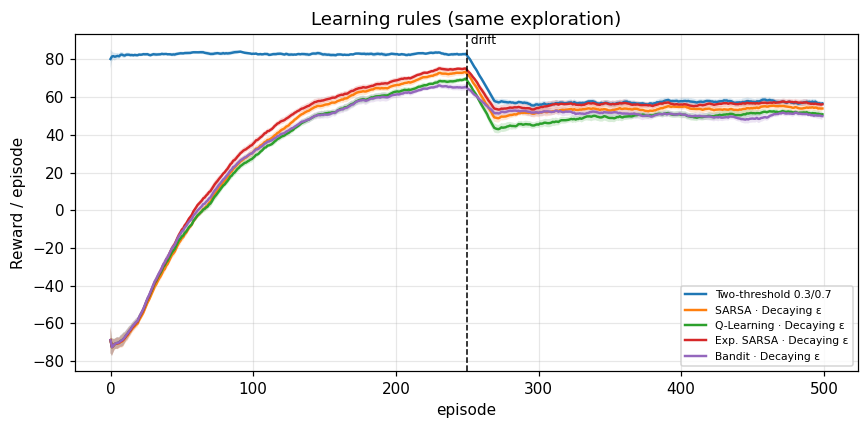

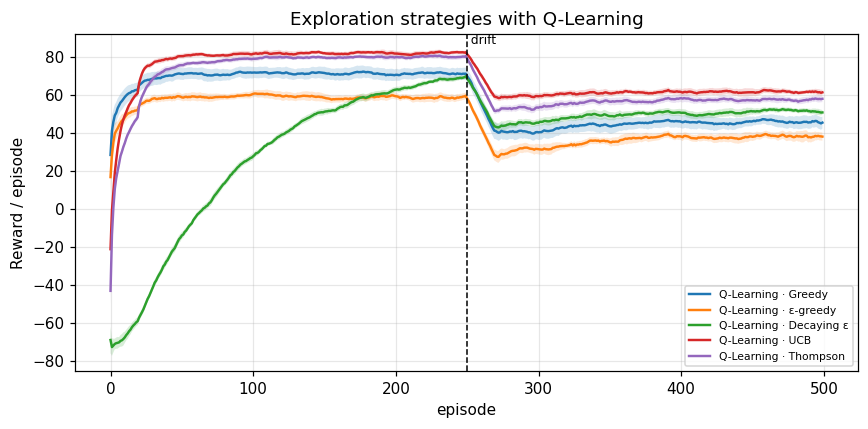

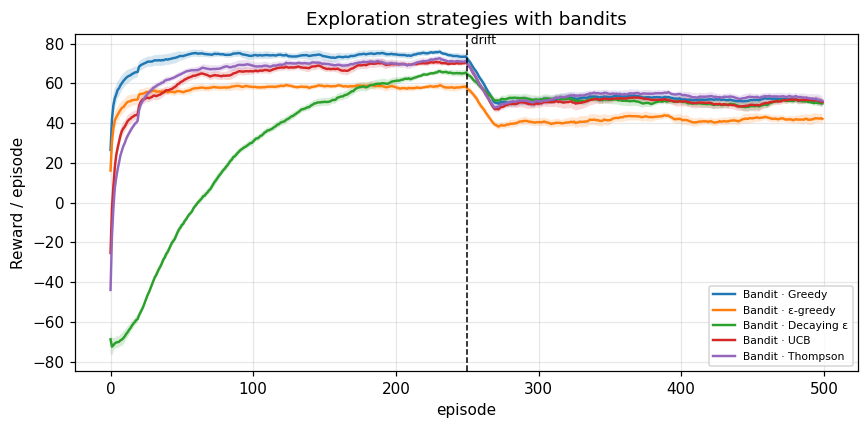

In [13]:
def smooth(H, w=20):
    c = np.cumsum(np.pad(H, ((0, 0), (1, 0))), axis=1)
    out = np.empty_like(H, dtype=float)
    for t in range(H.shape[1]):
        lo = max(0, t - w + 1)
        out[:, t] = (c[:, t + 1] - c[:, lo]) / (t + 1 - lo)
    return out

def plot_curves(names, title, metric=0, ax=None, fname=None, curves=None):
    curves = CURVES if curves is None else curves
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(8, 4))
    for n in names:
        S = smooth(curves[n][:, :, metric])
        m, c = S.mean(0), ci95(S)
        x = np.arange(len(m))
        ax.plot(x, m, label=n, lw=1.6)
        ax.fill_between(x, m - c, m + c, alpha=0.18)
    ax.axvline(CFG["DRIFT_EPISODE"], color="k", ls="--", lw=1)
    ax.text(CFG["DRIFT_EPISODE"], ax.get_ylim()[1], " drift", va="top", fontsize=8)
    ax.set_title(title); ax.set_xlabel("episode"); ax.set_ylabel(METRICS[metric] + " / episode")
    ax.legend(fontsize=7)
    if own:
        plt.tight_layout()
        if fname: plt.savefig(f"{RESULTS_DIR}/{fname}")
        plt.show()

plot_curves(["Two-threshold 0.3/0.7", "SARSA · Decaying ε", "Q-Learning · Decaying ε", "Exp. SARSA · Decaying ε",
             "Bandit · Decaying ε"], "Learning rules (same exploration)", fname="curves_algorithms.png")
plot_curves([n for n in AGENT_SPECS if n.startswith("Q-Learning")], "Exploration strategies with Q-Learning",
            fname="curves_exploration_q.png")
plot_curves([n for n in AGENT_SPECS if n.startswith("Bandit")], "Exploration strategies with bandits",
            fname="curves_exploration_bandit.png")

### 8c. Final evaluation metrics

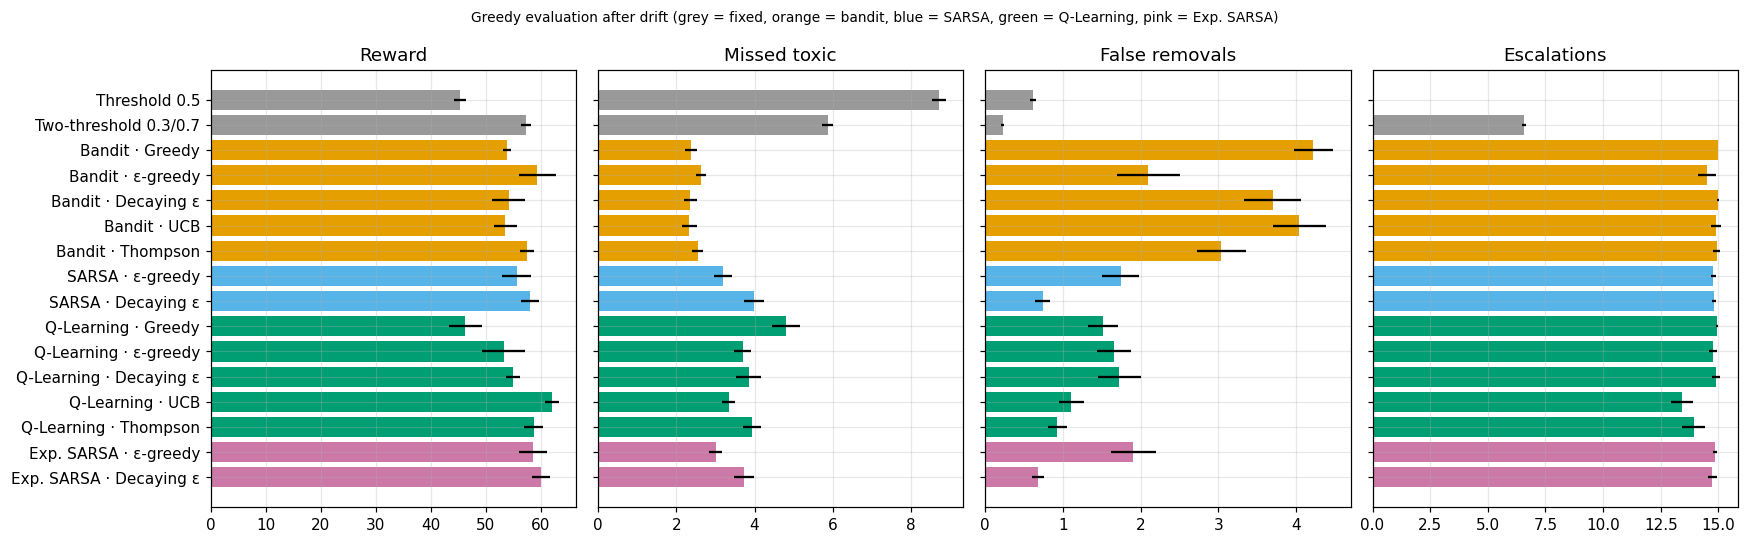

In [14]:
names = list(EVALS)
fig, axes = plt.subplots(1, 4, figsize=(16, 5), sharey=True)
for i, ax in enumerate(axes):
    m = [EVALS[n][:, i].mean() for n in names]
    c = [ci95(EVALS[n][:, i]) for n in names]
    colors = ["#999" if AGENT_SPECS[n][0] == "fixed" else
              {"bandit": "#e69f00", "sarsa": "#56b4e9", "qlearning": "#009e73",
               "expected_sarsa": "#cc79a7"}[AGENT_SPECS[n][0]] for n in names]
    ax.barh(names, m, xerr=c, color=colors)
    ax.set_title(METRICS[i]); ax.invert_yaxis() if i == 0 else None
plt.suptitle("Greedy evaluation after drift (grey = fixed, orange = bandit, blue = SARSA, green = Q-Learning, pink = Exp. SARSA)", fontsize=9)
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/eval_bars.png"); plt.show()

### 8d. What did the agents learn? Policy maps
Action chosen for each (score bin, budget level), mid-shift. On-policy SARSA tends to be more conservative near the budget limit than off-policy Q-Learning — compare the two maps.

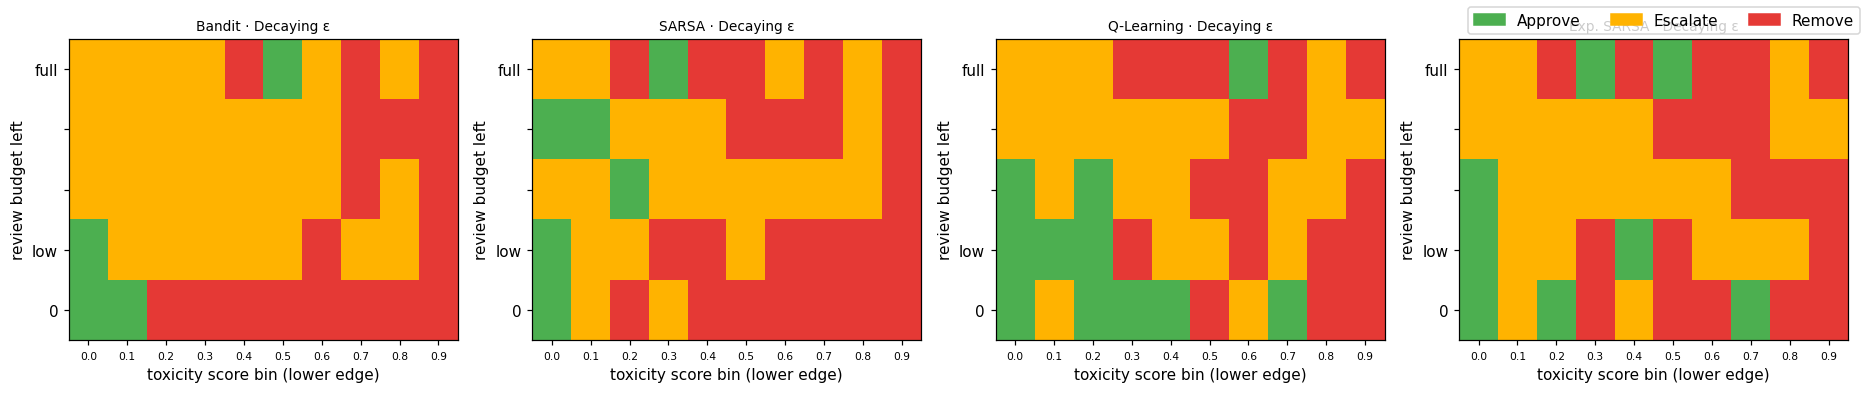

In [15]:
CMAP = ListedColormap(["#4caf50", "#ffb300", "#e53935"])

def policy_map(agent, time_bin=1):
    M = np.zeros((N_BUDGET_BINS, CFG["N_BINS"]), dtype=int)
    for b in range(N_BUDGET_BINS):
        for sb in range(CFG["N_BINS"]):
            M[b, sb] = int(agent.Q[(sb * N_BUDGET_BINS + b) * N_TIME_BINS + time_bin].argmax())
    return M

def plot_policy(agent, title, ax):
    ax.imshow(policy_map(agent), cmap=CMAP, vmin=0, vmax=2, aspect="auto", origin="lower")
    ax.set_xticks(range(CFG["N_BINS"]))
    ax.set_xticklabels([f"{i/CFG['N_BINS']:.1f}" for i in range(CFG["N_BINS"])], fontsize=7)
    ax.set_yticks(range(N_BUDGET_BINS)); ax.set_yticklabels(["0", "low", "", "", "full"])
    ax.set_xlabel("toxicity score bin (lower edge)"); ax.set_ylabel("review budget left")
    ax.set_title(title, fontsize=9); ax.grid(False)

show = ["Bandit · Decaying ε", "SARSA · Decaying ε", "Q-Learning · Decaying ε", "Exp. SARSA · Decaying ε"]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for n, ax in zip(show, axes):
    plot_policy(AGENTS[n], n, ax)
handles = [plt.Rectangle((0, 0), 1, 1, color=CMAP(i)) for i in range(3)]
fig.legend(handles, ACTIONS, loc="upper right", ncol=3)
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/policy_maps.png"); plt.show()

## 9. Sensitivity analysis: how much does a missed toxic comment cost?

done miss cost -2.0
done miss cost -5.0
done miss cost -10.0
done miss cost -20.0


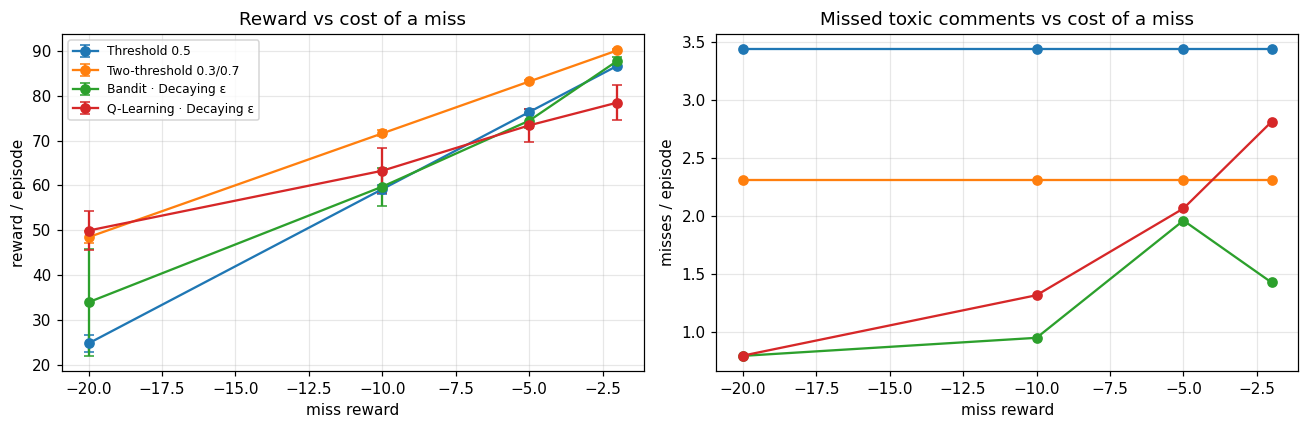

,miss_cost,policy,reward,reward_ci,missed,false_removals,escalations
0,-2.0,Threshold 0.5,86.70,0.37,3.44,0.74,0.00
1,-2.0,Two-threshold 0.3/0.7,90.14,0.19,2.31,0.29,3.54
2,-2.0,Bandit · Decaying ε,87.80,0.95,1.43,0.21,14.02
3,-2.0,Q-Learning · Decaying ε,78.49,3.93,2.82,0.75,14.59
4,-5.0,Threshold 0.5,76.39,0.61,3.44,0.74,0.00
5,-5.0,Two-threshold 0.3/0.7,83.19,0.37,2.31,0.29,3.54
6,-5.0,Bandit · Decaying ε,74.46,1.71,1.96,1.47,14.91
7,-5.0,Q-Learning · Decaying ε,73.41,3.71,2.07,1.05,14.79
8,-10.0,Threshold 0.5,59.19,1.03,3.44,0.74,0.00
9,-10.0,Two-threshold 0.3/0.7,71.62,0.69,2.31,0.29,3.54


In [16]:
SENS_SPECS = {k: AGENT_SPECS[k] for k in ["Threshold 0.5", "Two-threshold 0.3/0.7",
                                          "Bandit · Decaying ε", "Q-Learning · Decaying ε"]}
MISS_COSTS = [-2.0, -5.0, -10.0, -20.0]
sens_rows = []
for mc in MISS_COSTS:
    R = dict(REWARDS, miss=mc)
    _, ev, _ = run_all(SENS_SPECS, env_train_scores, env_train_labels, env_test_scores, env_test_labels,
                       R, CFG["N_SEEDS_SMALL"], drift=False, verbose=False)
    for n, E in ev.items():
        sens_rows.append(dict(miss_cost=mc, policy=n, reward=E[:, 0].mean(), reward_ci=ci95(E[:, 0]),
                              missed=E[:, 1].mean(), false_removals=E[:, 2].mean(), escalations=E[:, 3].mean()))
    print("done miss cost", mc)
SENS = pd.DataFrame(sens_rows)
SENS.to_csv(f"{RESULTS_DIR}/sensitivity.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for n in SENS_SPECS:
    d = SENS[SENS.policy == n]
    axes[0].errorbar(d.miss_cost, d.reward, yerr=d.reward_ci, marker="o", label=n, capsize=3)
    axes[1].plot(d.miss_cost, d.missed, marker="o", label=n)
axes[0].set_title("Reward vs cost of a miss"); axes[0].set_xlabel("miss reward"); axes[0].set_ylabel("reward / episode")
axes[1].set_title("Missed toxic comments vs cost of a miss"); axes[1].set_xlabel("miss reward"); axes[1].set_ylabel("misses / episode")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/sensitivity.png"); plt.show()
SENS.round(2)

## 10. Does classifier quality change what the agent can achieve? (Objective 6)

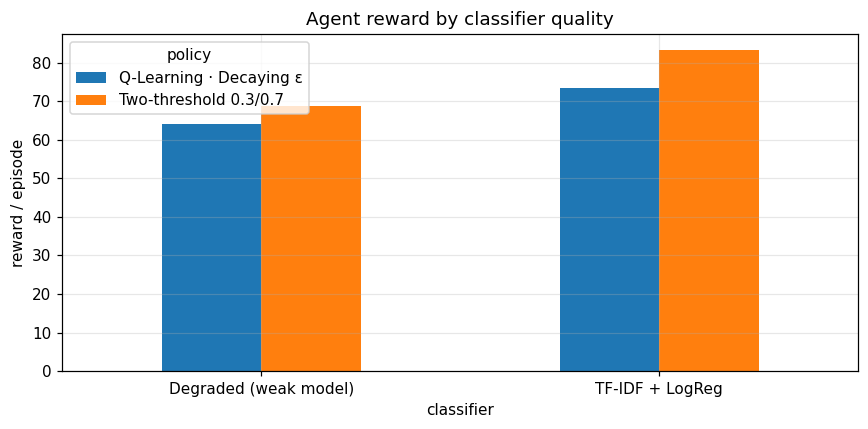

,classifier,AUC,policy,reward,missed,false_removals,escalations
0,TF-IDF + LogReg,0.972,Two-threshold 0.3/0.7,83.193,2.314,0.288,3.542
1,TF-IDF + LogReg,0.972,Q-Learning · Decaying ε,73.410,2.066,1.052,14.791
2,Degraded (weak model),0.891,Two-threshold 0.3/0.7,68.758,2.298,2.744,12.957
3,Degraded (weak model),0.891,Q-Learning · Decaying ε,64.151,3.657,1.405,15.000


In [17]:
CQ_SPECS = {k: AGENT_SPECS[k] for k in ["Two-threshold 0.3/0.7", "Q-Learning · Decaying ε"]}
cq_rows = []
for cname, (trs, trl, tes, tel) in CLASSIFIERS.items():
    _, ev, _ = run_all(CQ_SPECS, trs, trl, tes, tel, REWARDS, CFG["N_SEEDS_SMALL"], drift=False, verbose=False)
    for n, E in ev.items():
        cq_rows.append(dict(classifier=cname, AUC=clf_quality.loc[cname, "AUC"], policy=n,
                            reward=E[:, 0].mean(), missed=E[:, 1].mean(),
                            false_removals=E[:, 2].mean(), escalations=E[:, 3].mean()))
CQ = pd.DataFrame(cq_rows)
CQ.to_csv(f"{RESULTS_DIR}/classifier_quality.csv", index=False)

piv = CQ.pivot(index="classifier", columns="policy", values="reward")
ax = piv.plot.bar(figsize=(8, 4), rot=0)
ax.set_ylabel("reward / episode"); ax.set_title("Agent reward by classifier quality")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/classifier_quality.png"); plt.show()
CQ.round(3)

## 11. Answering the research questions
The cell below prints auto-generated observations from **your** run. Use them as a starting point for the Results & Discussion section — check them against the plots before writing.

In [18]:
def mean_r(n): return EVALS[n][:, 0].mean()
best = RESULTS.iloc[0]["Policy"]
best_fixed = max(["Threshold 0.5", "Two-threshold 0.3/0.7"], key=mean_r)
learned = [n for n in AGENT_SPECS if AGENT_SPECS[n][0] != "fixed"]
best_learned = max(learned, key=mean_r)
print(f"RQ1  Best learned policy: {best_learned} ({mean_r(best_learned):.1f}) vs best fixed: {best_fixed} ({mean_r(best_fixed):.1f}).")
s, q = "SARSA · Decaying ε", "Q-Learning · Decaying ε"
print(f"RQ2  SARSA vs Q-Learning: reward {mean_r(s):.1f} vs {mean_r(q):.1f}; escalations "
      f"{EVALS[s][:,3].mean():.1f} vs {EVALS[q][:,3].mean():.1f}; training reward during drift window "
      f"{RESULTS.set_index('Policy').loc[s,'Right after drift']} vs {RESULTS.set_index('Policy').loc[q,'Right after drift']}.")
algo_spread = np.ptp([mean_r(n) for n in ["Bandit · Decaying ε", s, q, "Exp. SARSA · Decaying ε"]])
expl_spread = np.ptp([mean_r(n) for n in AGENT_SPECS if n.startswith("Q-Learning")])
print(f"RQ3  Reward spread across learning rules (decaying ε): {algo_spread:.1f}; across exploration strategies (Q-Learning): {expl_spread:.1f}.")
cq = CQ[CQ.policy == q].set_index("classifier")["reward"]
print("RQ4  Q-Learning reward by classifier:", {k: round(v, 1) for k, v in cq.items()})
print(f"\nOverall best policy: {best}")

RQ1  Best learned policy: Q-Learning · UCB (62.0) vs best fixed: Two-threshold 0.3/0.7 (57.3).
RQ2  SARSA vs Q-Learning: reward 58.0 vs 55.0; escalations 14.8 vs 14.9; training reward during drift window 50.6 vs 44.8.
RQ3  Reward spread across learning rules (decaying ε): 5.9; across exploration strategies (Q-Learning): 15.7.
RQ4  Q-Learning reward by classifier: {'TF-IDF + LogReg': 73.4, 'Degraded (weak model)': 64.2}

Overall best policy: Q-Learning · UCB


### Save all results (figures + CSVs) for the report

In [19]:
shutil.make_archive("rl_moderation_results", "zip", RESULTS_DIR)
print("Saved rl_moderation_results.zip with:", sorted(os.listdir(RESULTS_DIR)))
if IN_COLAB:
    from google.colab import files
    files.download("rl_moderation_results.zip")

Saved rl_moderation_results.zip with: ['classifier_quality.csv', 'classifier_quality.png', 'curves_algorithms.png', 'curves_exploration_bandit.png', 'curves_exploration_q.png', 'eval_bars.png', 'main_results.csv', 'policy_maps.png', 'score_distribution.png', 'sensitivity.csv', 'sensitivity.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Interactive interface (Gradio)
Four tabs:
1. **Moderate a comment** – type any comment, set the remaining review budget and queue position, pick an agent → see score, decision and Q-values.
2. **Simulate a moderation shift** – run an agent over a queue of held-out comments (offensive words masked).
3. **Policy map** – see the learned decision table of any agent.
4. **Results** – the comparison table.

A public link appears below the cell (valid ~72 h while the runtime is on).

In [20]:
import re
import gradio as gr

LEARNED_NAMES = [n for n in AGENTS if hasattr(AGENTS[n], "Q")]
ALL_NAMES = list(AGENTS)
MASK_WORDS = ["fuck", "shit", "bitch", "cunt", "dick", "asshole", "bastard", "idiot", "stupid", "moron",
              "faggot", "nigger", "retard", "whore", "slut", "dumb", "loser", "suck"]
MASK_RE = re.compile(r"\b(\w*(" + "|".join(MASK_WORDS) + r")\w*)\b", re.I)

def mask_text(t, n=160):
    t = MASK_RE.sub(lambda m: m.group(1)[0] + "*" * (len(m.group(1)) - 1), str(t).replace("\n", " "))
    return t[:n] + ("…" if len(t) > n else "")

class _FakeEnv:
    def __init__(self, p, budget): self.current_score, self.budget = p, budget

ICON = {0: "✅ APPROVE", 1: "🧑‍⚖️ ESCALATE to human review", 2: "⛔ REMOVE"}

def ui_moderate(text, budget, position, agent_name):
    if not text or not text.strip():
        return "Type a comment first.", None, None
    p = float(score_texts([text])[0])
    budget, position = int(budget), int(position)
    s = encode_state(p, budget, position)
    ag = AGENTS[agent_name]
    a = ag.act(s, 10**9, _FakeEnv(p, budget), greedy=True)
    base = ThresholdAgent(0.3, 0.7).act(s, 0, _FakeEnv(p, budget))
    md_out = (f"### {ICON[a]}\n"
              f"**Toxicity score:** {p:.3f}  \n"
              f"**State:** score bin {min(int(p*CFG['N_BINS']), CFG['N_BINS']-1)}, budget {budget}/{CFG['BUDGET']}, "
              f"comment {position}/{CFG['EP_LEN']} of the shift  \n"
              f"**Two-threshold baseline would:** {ACTIONS[base]}")
    if hasattr(ag, "Q"):
        q = ag.Q[s]
        qdf = pd.DataFrame({"Action": ACTIONS, "Q-value (expected return)": np.round(q, 3),
                            "Times tried in training": ag.N[s].astype(int)})
        fig, ax = plt.subplots(figsize=(5, 2.6))
        ax.barh(ACTIONS, q, color=[CMAP(i) for i in range(3)])
        ax.set_title(f"{agent_name}: Q-values in this state"); ax.set_xlabel("Q-value")
        plt.tight_layout()
        return md_out, qdf, fig
    return md_out + "\n\n(Fixed rule — no Q-values.)", None, None

def ui_simulate(agent_name, n_comments, toxic_rate, seed):
    ag = AGENTS[agent_name]
    env = ModerationEnv(env_test_scores, env_test_labels, int(seed), REWARDS)
    env.set_conditions(float(toxic_rate), None)
    s = env.reset()
    rows, tot = [], 0.0
    for _ in range(int(n_comments)):
        idx, p, b = int(env.ep_idx[env.t]), env.current_score, env.budget
        a = ag.act(s, 10**9, env, greedy=True)
        s2, r, done, out = env.step(a)
        tot += r
        rows.append({"#": len(rows) + 1, "Comment (masked)": mask_text(env_test_df.text.iloc[idx]),
                     "Score": round(p, 3), "True label": "toxic" if env_test_labels[idx] else "clean",
                     "Budget left": b, "Action": ACTIONS[a], "Outcome": out, "Reward": r})
        if done: break
        s = s2
    d = pd.DataFrame(rows)
    summary = (f"**Total reward:** {tot:.1f} | **Missed toxic:** {(d.Outcome.isin(['miss','no_budget_miss'])).sum()} | "
               f"**False removals:** {(d.Outcome=='false_remove').sum()} | **Escalations:** {(d.Outcome=='escalated').sum()} "
               f"| **Budget used:** {CFG['BUDGET']-env.budget}/{CFG['BUDGET']}")
    return summary, d

def ui_policy(agent_name, time_bin):
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ag = AGENTS[agent_name]
    ax.imshow(policy_map(ag, int(time_bin)), cmap=CMAP, vmin=0, vmax=2, aspect="auto", origin="lower")
    ax.set_xticks(range(CFG["N_BINS"]))
    ax.set_xticklabels([f"{i/CFG['N_BINS']:.1f}" for i in range(CFG["N_BINS"])])
    ax.set_yticks(range(N_BUDGET_BINS)); ax.set_yticklabels(["none", "low", "mid", "high", "full"])
    ax.set_xlabel("toxicity score"); ax.set_ylabel("review budget left"); ax.grid(False)
    ax.set_title(f"{agent_name} (shift quarter {int(time_bin)+1}/4)")
    fig.legend([plt.Rectangle((0, 0), 1, 1, color=CMAP(i)) for i in range(3)], ACTIONS, loc="lower center", ncol=3)
    plt.tight_layout(rect=(0, 0.08, 1, 1))
    return fig

with gr.Blocks(title="ModerateRL") as demo:
    gr.Markdown("# 🛡️ ModerateRL — Learning When to Act\nReinforcement-learning moderation policies on Jigsaw toxicity scores"
                + ("  \n⚠️ *Running on the DEMO corpus.*" if DEMO_MODE else ""))
    with gr.Tab("Moderate a comment"):
        with gr.Row():
            with gr.Column():
                txt = gr.Textbox(label="Comment", lines=4, placeholder="Type a comment…")
                agent_dd = gr.Dropdown(ALL_NAMES, value="Q-Learning · Decaying ε", label="Policy")
                bud = gr.Slider(0, CFG["BUDGET"], value=CFG["BUDGET"] // 2, step=1, label="Human reviews left")
                pos = gr.Slider(0, CFG["EP_LEN"] - 1, value=CFG["EP_LEN"] // 2, step=1, label="Position in shift")
                btn = gr.Button("Decide", variant="primary")
                gr.Examples([["Thanks for adding the source, the article reads much better now."],
                             ["You are a complete idiot, stop editing this page."],
                             ["This argument is dumb but I see where you are coming from."]], inputs=txt)
            with gr.Column():
                out_md = gr.Markdown()
                out_q = gr.Dataframe(label="Q-values")
                out_plot = gr.Plot()
        btn.click(ui_moderate, [txt, bud, pos, agent_dd], [out_md, out_q, out_plot])
    with gr.Tab("Simulate a moderation shift"):
        with gr.Row():
            sim_agent = gr.Dropdown(ALL_NAMES, value="Q-Learning · Decaying ε", label="Policy")
            sim_n = gr.Slider(10, CFG["EP_LEN"], value=50, step=10, label="Comments in queue")
            sim_tox = gr.Slider(0.05, 0.5, value=CFG["TOXIC_RATE"], step=0.05, label="Toxic share")
            sim_seed = gr.Number(value=1, precision=0, label="Seed")
        sim_btn = gr.Button("Run shift", variant="primary")
        sim_sum = gr.Markdown()
        sim_tab = gr.Dataframe(wrap=True)
        sim_btn.click(ui_simulate, [sim_agent, sim_n, sim_tox, sim_seed], [sim_sum, sim_tab])
    with gr.Tab("Policy map"):
        with gr.Row():
            pm_agent = gr.Dropdown(LEARNED_NAMES, value="Q-Learning · Decaying ε", label="Learned policy")
            pm_time = gr.Slider(0, N_TIME_BINS - 1, value=1, step=1, label="Shift quarter (0 = start)")
        pm_plot = gr.Plot()
        pm_agent.change(ui_policy, [pm_agent, pm_time], pm_plot)
        pm_time.change(ui_policy, [pm_agent, pm_time], pm_plot)
        demo.load(ui_policy, [pm_agent, pm_time], pm_plot)
    with gr.Tab("Results"):
        gr.Markdown("Greedy evaluation on the held-out pool after drift (mean ± 95% CI over seeds).")
        gr.Dataframe(RESULTS, wrap=True)

demo.launch(share=IN_COLAB, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e6d6a6dbbf76394050.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
